# **Task 1**

In [17]:
import pandas as pd #import all libraries needed, pandas for data handling
import numpy as np #numerical functions
import seaborn as sns #visualistaion
import matplotlib.pyplot as plot #plot graphs
from sklearn.preprocessing import StandardScaler #standardisation for numerical data
from sklearn.linear_model import LinearRegression # create linear regression model
from sklearn.model_selection import KFold # 10 fold cross validation
from sklearn.metrics import r2_score #calculate R2 score for model
import itertools # test all feature combinations for subset
import statsmodels.api as sm # also for subset for adjusted R2 and regression analysis

df = pd.read_csv("finanical_report_2018.csv", na_values=["n/a", "NaN", "Na", " ", ""]) #import dataset


def look_at_data(dataset): # explore dataset to show first 10 columns and null values
    print(dataset.head(10)) 
    print(dataset.info(),"\n") 
    print("dataset shape: ", dataset.shape,"\n") 
    print(dataset.describe()) 

df["Size"]= pd.to_numeric(df["Size"], errors="coerce") #issue: wasn't fixing object to float had to move it up, Size changed to numeric as it was set to object

look_at_data(df)

null_masks = df.isnull().any(axis=1) #filter rows with missing values and display them
null_data = df[null_masks]
null_data

for column in df.columns: #find and print rows and columns with missing values like stock code
    if column != "Stock Code":
        missingandwrong = df[df[column].isnull()]

        if len(missingandwrong) > 0:
            print("\nFeature:", column)

            print(missingandwrong[["Stock Code"]])
            
for column in df: #print uniques values in columns 
    print(column, ":")
    print(df[column].unique(), "\n")

for column in df.columns: #replace missing values
    most_common = df[column].mode()[0]
    df[column] = df[column].fillna(most_common)
    
print(df.isnull().sum()) #check for remained null values
df.to_csv("cleaned_dataset.csv", index=False) #saved in jupyter

   Stock Code  Market Value of Equity  Total Market Value  Stock Return  \
0      900939                57992.00           119608.50      0.089254   
1      900956               153180.00           313020.00      0.073942   
2      900952                68624.55            68624.55      0.069444   
3      900933              1526013.44          1526013.44      0.071170   
4      900957               102304.00           194044.00      0.049056   
5      900937                51840.00            51840.00      0.121494   
6      900928               156432.43           156432.43      0.031073   
7      900943                39120.00            39120.00      0.131947   
8      900927                53506.20            53506.20      0.076305   
9      900938                90669.35            90669.35      0.065135   

   Total Investment Expenditure  Amortization and Depreciation   Book Value  \
0                    736.498400                     529.177000   18557.4400   
1               

For Task 1, I first inserted the dataset so I can explore and clean it, I used the help of week 5 worksheet to use exploring method. I used functions like (head()), (info()), (shape()), and (describe()) to undertsnad the dataset and data types, most importantly to help with looking for missing or wrong values. 

Missing values were find out using the isnull() function with null mask to filter all rows with missing values and display them. A loop was used to print the stock codes and column feature names for companies also containing wrong values for part a. 

The unique() method was used to search values in each column to identify missing/wrong values. for the exploring part, I noticed that Size column was written as an object datatyype instead of numeric datatype. The column was fixed to numeric by using 'pd.to_numeric'. 

Missing values were replaced using the most frequent value from each column with the mode() function. Finally the dataset was checked for no more missing values and the cleaned dataset was saved in my files. 

# **Task 2**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3845 entries, 0 to 3844
Data columns (total 13 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Stock Code                           3845 non-null   int64  
 1   Market Value of Equity               3845 non-null   float64
 2   Total Market Value                   3845 non-null   float64
 3   Stock Return                         3817 non-null   float64
 4   Total Investment Expenditure         3845 non-null   float64
 5   Amortization and Depreciation        3845 non-null   float64
 6   Book Value                           3845 non-null   float64
 7   Operating Income after Depreciation  3845 non-null   float64
 8   Annual Dividends                     3845 non-null   float64
 9   Leverage                             3845 non-null   float64
 10  Cash                                 3845 non-null   float64
 11  Age                           

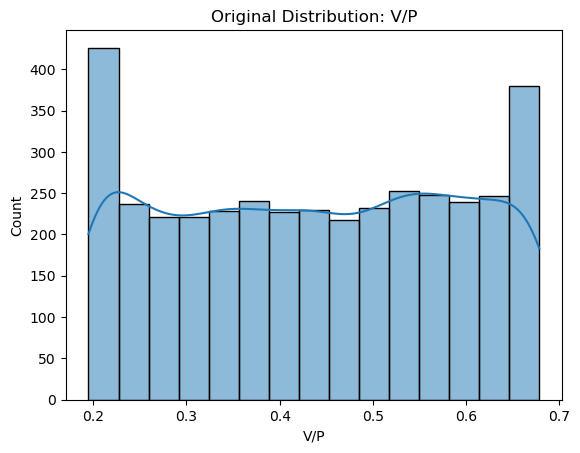

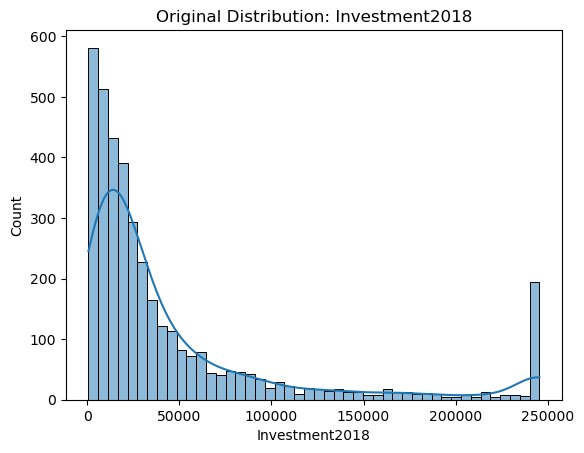

In [5]:
df = pd.read_csv("finanical_report_2018.csv") #load cleaned dataset to work with
df.head() #prints first 5 rows
df.info() #prints info about column names, data types

#V/P = ((1-1.24*0.12)*Book_Value +1.24*1.12* Operating_Income_after_Depreciation -1.24*0.12* Annual_Dividends)/ Market_Value_of_Equity
#𝑰𝒏𝒗𝒆𝒔𝒕𝒎𝒆𝒏𝒕𝟐𝟎𝟏𝟖 = 𝑇𝑜𝑡𝑎𝑙 𝐼𝑛𝑣𝑒𝑠𝑡𝑚𝑒𝑛𝑡 𝐸𝑥𝑝𝑒𝑛𝑑𝑖𝑡𝑢𝑟𝑒 − 𝐴𝑚𝑜𝑟𝑡𝑖𝑧𝑎𝑡𝑖𝑜𝑛 𝑎𝑛𝑑 𝐷𝑒𝑝𝑟𝑒𝑐𝑖𝑎𝑡𝑖𝑜
#used the above formulas to create V/P and dataset Investement for 2018 
df["V/P"] = (((1-1.24*0.12) * df["Book Value"] + 1.24*1.12 * df["Operating Income after Depreciation"] - 1.24*0.12 * df["Annual Dividends"]) / df["Market Value of Equity"])
df["Investment2018"] = (df["Total Investment Expenditure"] - df["Amortization and Depreciation"])

for col in ["V/P", "Investment2018"]: df[col] = df[col].clip(df[col].quantile(0.05), df[col].quantile(0.95)) #reduce outliers with clip method
    
for col in ["V/P", "Investment2018"]: #using the new features to understand their data by plotting
    plot.figure() # new figure for each plot
    sns.histplot(df[col], kde=True) #histogram with dencity curve
    plot.title(f"Original Distribution: {col}") #heading/title for the graph plot
    plot.show() #displays the plot

scaler = StandardScaler() #standardisation
num_cols = df.select_dtypes(include=np.number).columns.drop("Stock Code") #selected numeric columns 
scaler.fit(df[num_cols]) #fit scaler
df[num_cols] = scaler.fit_transform(df[num_cols]) #transform columns

df.to_csv("cleaned_dataset.csv", index=False)

For normalisation, I used Standardisation using StandarScaler to rescale all numerical features so they have mean of 0 and standard deviation of 1. This ensures that all variables are on the same scale, so no features with large values like Total Market Value influence small values. I chose Standardisation rather than Min-Max Normalisation as this method compresses everything into fixed 0-to-1 range the Min-Max, it's not the best with outliers, one large value can cluster the other data with extreme outliers. Standardisation is more sutable for datasets containing outliers. 

To plot, Histograms were used to explore distribution of the new features created V/P and Investment 2018 with KDE. These plots show how the data is spread and the shape it follows like skewed or symmetric. By plotting these, I could identify whether the features followed a normal distribution or exhibits skeweness that can affect the regression model.  

Outliers were identified through histogram plots by the long tails and spikes, to handle these without affecting data points, I used the method .clip() method to cap values at 5th and 95th percentiles. Which is why 2 long bars as seen on the right and left that represent extreme outliers. By using this method with Standardisation, I kept the model stable and improved model readability.

# **Task 3**

In [6]:
df.describe()

,Stock Code,Market Value of Equity,Total Market Value,Stock Return,Total Investment Expenditure,Amortization and Depreciation,Book Value,Operating Income after Depreciation,Annual Dividends,Leverage,Cash,Age,V/P,Investment2018
count,3845.000000,3.845000e+03,3.845000e+03,3.817000e+03,3.845000e+03,3.845000e+03,3.845000e+03,3.845000e+03,3.845000e+03,3.845000e+03,3.845000e+03,3.845000e+03,3.845000e+03,3.845000e+03
mean,322256.015605,1.663169e-17,-1.293576e-17,5.584564e-17,4.435117e-17,1.293576e-17,-9.239828e-18,-3.695931e-18,-1.385974e-17,9.979014e-17,-2.217559e-17,-5.174303e-17,-1.672409e-16,7.391862e-17
std,273220.065625,1.000130e+00,1.000130e+00,1.000131e+00,1.000130e+00,1.000130e+00,1.000130e+00,1.000130e+00,1.000130e+00,1.000130e+00,1.000130e+00,1.000130e+00,1.000130e+00,1.000130e+00
min,1.000000,-2.201696e-01,-2.599892e-01,-5.971885e+00,-2.192085e-01,-2.017441e-01,-1.989407e-01,-1.851611e-01,-1.841846e-01,-1.727872e+00,-2.185596e-01,-2.843437e+00,-1.590501e+00,-7.388295e-01
25%,2510.000000,-1.864418e-01,-2.117731e-01,-4.619581e-01,-1.876306e-01,-1.723639e-01,-1.728591e-01,-1.608422e-01,-1.606814e-01,-8.578017e-01,-1.874870e-01,-4.958827e-01,-8.785265e-01,-5.917266e-01
50%,300485.000000,-1.572790e-01,-1.779860e-01,-1.757496e-01,-1.581892e-01,-1.455021e-01,-1.446847e-01,-1.353611e-01,-1.357073e-01,-1.596562e-02,-1.557702e-01,2.866353e-01,7.711080e-03,-3.974038e-01
75%,600780.000000,-8.252578e-02,-8.151422e-02,2.777587e-01,-8.032207e-02,-7.853384e-02,-7.466254e-02,-6.993570e-02,-7.349246e-02,8.747206e-01,-7.919044e-02,7.904643e-01,8.712722e-01,7.467336e-02
max,900957.000000,2.767393e+01,2.651377e+01,1.569775e+01,2.586298e+01,2.897456e+01,3.497539e+01,4.019061e+01,3.484729e+01,1.721516e+00,2.592279e+01,1.103892e+00,1.593369e+00,3.167969e+00


Descriptive statistical summary was created using the .describe() function. This shows key important statistical measures including mean, standard deviation (std), minimum, maximum, and quartile values for each feature. These figures help understand the distribution and spread of the dataset before using multi regression model.

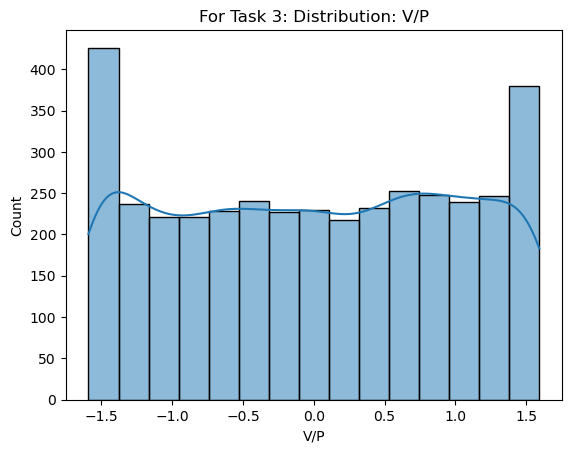

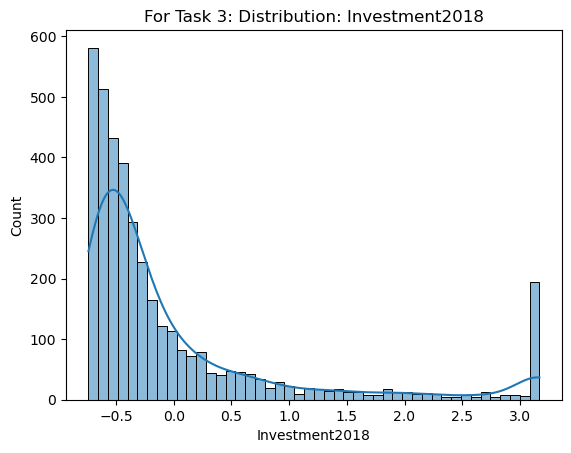

In [7]:
for col in ["V/P", "Investment2018"]: #using the new features to understand their data by plotting
    plot.figure() # new figure for each plot
    sns.histplot(df[col], kde=True) #histogram with dencity curve
    plot.title(f"For Task 3: Distribution: {col}") #heading/title for the graph plot
    plot.show() #displays the plot

Distribution plots were created for all numerical features using histograms with KDE (Kernel Density Estimation). The histogram shows the shape of the data, outliers, and if it's a normal distribution. Understanding the distribution is important before using multi regression, as the model perform better when variables are normally distributed and well-scaled. 

# **Task 4**

In [9]:
financial = pd.read_csv("cleaned_dataset.csv") #load cleaned dataset of financial report 2018 and the investment 2019
investment = pd.read_csv("Investment_2019.csv")

financial.columns = financial.columns.str.strip() #clean column names
investment.columns = investment.columns.str.strip()

financial["Stock Code"] = financial["Stock Code"].astype(str) #using same datatype for merging
investment["Stock Code"] = investment["Stock Code"].astype(str)

df_model = pd.merge(financial, investment, on="Stock Code") #merging datasets 


df_model = df_model.replace("#NUM!", np.nan) #missing and invalid values fixed using NaN

for col in df_model.columns: #convert features to numeric values except Stock Code
    if col != "Stock Code":
        df_model[col] = pd.to_numeric(df_model[col], errors="coerce")

df_model = df_model.fillna(df_model.mean(numeric_only=True)) #missing values replaced with mean

Linear Regression model was developed to forecast the 2019 investment value of listed firms based on their financial variables in 2018. The predictors that have been used to construct the linear regression model were:
V/P, Leverage, Cash, Age, Size, Stock Return, and Investment2018, where Investment2019 was the dependent variable. The LinearRegression model available in the Scikit-Learn library has been used for training the linear regression model.

In [18]:
features = ["V/P", "Leverage", "Cash", "Age", "Size", "Stock Return", "Investment2018"] #independent variables
X = df_model[features] #matrix using the features
y=df_model["Investment2019"] #dependent variables

#10 fold cross validation
model = LinearRegression()

kf = KFold(n_splits=10, shuffle=True, random_state=42)

r2_scores = [] #empty list to store R2 scores

for train_index, test_index in kf.split(X): #loop through each fold

    X_train, X_test = X.iloc[train_index], X.iloc[test_index] #splitted into training and testing sets 
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    r2_scores.append(r2_score(y_test, y_pred))  #calculate r2

print("R2 Scores per fold:", r2_scores)
print("\nAverage R2 Score:", np.mean(r2_scores))


R2 Scores per fold: [-0.17900086594828957, 0.042576028224480256, -0.20331506001731103, -1.3535867205557839, -0.8388064249948612, -0.21503213562928303, 0.5128992804795243, 0.043404943734378865, 0.2770909570317873, -5.413691047681729]

Average R2 Score: -0.7327461045357087


In order to measure the performance of the model accurately, we made use of 10-fold cross-validation. Here, the data was divided into 10 partitions of equal sizes. For each fold, 9 parts of the data were utilized for training while 1 part of the data was kept aside for testing purposes. After repeating this procedure 10 times, the performance of the model was determined by taking the mean value of R² score for all folds.

In [19]:
n = len(y) #calculate adjusted R2 - no. of  rows
k = X.shape[1] #no. of features

adjusted_r2 = 1 - ((1 - np.mean(r2_scores)) * (n - 1)) / (n - k - 1)

print("Adjusted R2:", adjusted_r2)

Adjusted R2: -0.735907225914846


djusted R2 was chosen to evaluate the subset of features, determining whether all selected features added significantly to the predictive performance. The reason for choosing this measure is that it discourages unnecessary features and helps avoid overfitting.

In [20]:
#function to train regression model for a subset of features
def process_subset(features_subset, X, y):
    X_subset = sm.add_constant(X[list(features_subset)]) #constant for regression intercept
    model = sm.OLS(y, X_subset).fit() #train OLS

    return {"features": features_subset,"AdjR2": model.rsquared_adj }


def best_subset(k, X, y): #find best subset of features
    results = []

    for combo in itertools.combinations(features, k): #test all combinations of features
        results.append(process_subset(combo, X, y))

    df = pd.DataFrame(results) #convert into dataframe
    return df.loc[df["AdjR2"].idxmax()] #highest adjusted R2


best_models = [] #list for best models

for k in range(1, len(features) + 1):
    best_models.append(best_subset(k, X, y))

best_df = pd.DataFrame(best_models)

overall_best = best_df.loc[best_df["AdjR2"].idxmax()] # finding overall best feature

print("Best feature subset:", overall_best["features"])
print("Best Adjusted R2:", overall_best["AdjR2"])

Best feature subset: ('V/P', 'Leverage', 'Cash', 'Size', 'Investment2018')
Best Adjusted R2: 0.259923061355263


Adjust R² has been used to analyze the combination of the features to determine the best combination of the variables. It was considered appropriate for this process since it punishes the number of unnecessary variables which ensures that only important features that enhance the prediction capabilities of the model are used. With the exhaustive subset selection, various combinations of the variables have been analyzed. The best combination of the variables according to Adjust R² is the following: V/P, Leverage, Cash, Size, and Investment2018. Two features that had been found to be irrelevant are Age and Stock Return. Their exclusion led to a significant improvement in Adjust R² to about 0.2599. Even after analyzing manually the feature combination, Adjust R² gave a negative score (-0.7339).

In [21]:
best_features = list(overall_best["features"]) #best features into list

X_best = df_model[best_features] #new matrix using best features

final_model = LinearRegression() #creating regression model here
final_model.fit(X_best, y)

y_pred = final_model.predict(X_best) #predict investment values

The best combination of the feature subset found by using an exhaustive search method based on Adjusted R² was chosen for the final model. The feature subset was chosen and the model was trained again using the linear regression model, such that only those features which were statistically significant were considered. Then the model was trained again using the optimal feature subset, and predictions were made regarding the value of Investment2019 using these optimal feature subsets.

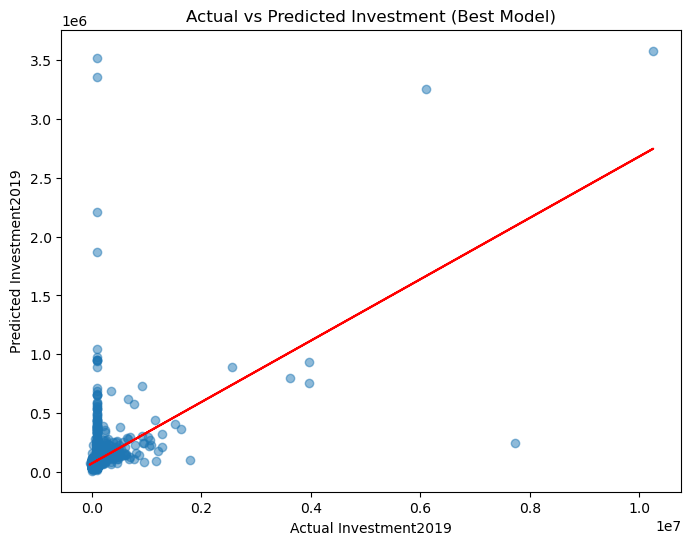

In [22]:
plot.figure(figsize=(8,6)) #create scatter plot

plot.scatter(y, y_pred, alpha=0.5) #actual plot  and predicted values

# best fit line
m, b = np.polyfit(y, y_pred, 1)
plot.plot(y, m*y + b, color="red") #plot regression line
#axis labels and title
plot.xlabel("Actual Investment2019")
plot.ylabel("Predicted Investment2019")
plot.title("Actual vs Predicted Investment (Best Model)")

plot.show() #shows graph

The predictions of the final model were evaluated based on the scatter diagram comparing the actual and predicted investment values. If the data points are clustered around the diagonal trend line, then the fit is good. This graph allows us to evaluate the quality of prediction of investment values in 2019.

In [16]:
financial = financial.replace(['#NUM!', 'NUM!', 'n/a', ' '], np.nan) #financial dataset for prediction

for col in best_features: #convert to numeric values and remove missing values
    financial[col] = pd.to_numeric(financial[col], errors='coerce')
    financial[col] = financial[col].fillna(financial[col].mean())

financial["Predicted_Investment2019"] = final_model.predict(financial[best_features]) #predict investment for 2018 using trained model

financial.to_csv("new_investment_2019.csv", index=False) #saving dataset

After training the model with the optimal feature set, the model was utilized for predicting the Investment2019 dataset. In this case, the trained model was used to predict the value of investment for each company in the data set. The predicted values were stored in a newly created column referred to as "Predicted_Investment2019". The updated data set was saved as a CSV file for future purposes.